# Evaluación Grupal · EduAnalytics (CRISP-DM, Fases 1–4)
### Proyecto: Análisis de Patrones de Uso de IA Generativa y Riesgo de Burnout Estudiantil

---

### Datos Generales del Proyecto
* **Institución Educativa:** Universidad Privada Franz Tamayo (UNIFRANZ)
* **Facultad / Carrera:** Ingeniería de Sistemas
* **Materia:** Minería de Datos
* **Integrantes del Grupo:**
  1. **Milenka Melody Chuquimia Osco**
  2. **Edson Teddy Tito Chuquimia**
  3. **Carlos Daniel Valverde Mendoza**
  4. **Alvaro Luis Carlos del Carpio Blanco**
  5. **Marcelo Josue Escobar Chipana**

---

### Propósito del Cuaderno: Modelado con Árbol de Decisión para Clasificación (CART)
Este documento implementa de forma integral, didáctica y autónoma el flujo de **Árbol de Decisión para Clasificación** correspondiente a la Fase 4 de CRISP-DM. Se estructuran las siguientes etapas:
1. **Definición del Problema y Justificación de Variables.**
2. **Preparación y Preprocesamiento de Datos (específico para árboles, sin fuga de información).**
3. **Entrenamiento del Árbol Inicial vs. Árbol Optimizado mediante Validación Cruzada (CV de 5 Pliegues).**
4. **Evaluación de Métricas (Accuracy, Precision, Recall, F1, Matriz de Confusión e Importancia de Variables Gini).**
5. **Visualización y Comunicación (Diagrama `plot_tree`, Reglas Explícitas `export_text`, Curvas ROC Multiclase y Matriz de Confusión).**
6. **Interpretación Accesible de Hallazgos y Puntos de Corte para la Gestión Educativa.**

> **Autonomía:** Este cuaderno se ejecuta de principio a fin sin requerir módulos auxiliares externos ni archivos precalculados. La única dependencia necesaria es el dataset `ai_student_impact_dataset (1).csv`.


## 1 · Configuración del Entorno y Carga Autónoma de Datos


In [1]:
from pathlib import Path
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, FunctionTransformer, label_binarize
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    precision_recall_fscore_support, confusion_matrix, roc_curve, auc
)
from IPython.display import display, Markdown

# Configuración de estilo visual y advertencias
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)

SEED = 42
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)
sns.set_theme(style='whitegrid', context='notebook')

FUENTE = 'Fuente: Kaggle «AI Usage & Student Academic Performance Analysis» v1 (CC0); cálculo propio.'

# Búsqueda dinámica y flexible del dataset
rutas_candidatas = [
    Path('ai_student_impact_dataset (1).csv'),
    Path('./ai_student_impact_dataset (1).csv'),
    Path('../dataset/ai_student_impact_dataset (1).csv'),
    Path('dataset/ai_student_impact_dataset (1).csv'),
    Path('../../dataset/ai_student_impact_dataset (1).csv')
]

RUTA_CSV = next((p for p in rutas_candidatas if p.is_file()), None)
if RUTA_CSV is None:
    raise FileNotFoundError("No se encontró el dataset 'ai_student_impact_dataset (1).csv'. Colóquelo en la carpeta actual o en dataset/.")

df = pd.read_csv(RUTA_CSV, sep=';', encoding='utf-8-sig')
print("Entorno cargado con éxito:")
print(f"• Python: {sys.version.split()[0]} | pandas: {pd.__version__} | scikit-learn: {sklearn.__version__}")
print(f"• Dataset localizado: {RUTA_CSV.resolve()}")
print(f"• Registros leídos: {df.shape[0]:,} filas × {df.shape[1]} columnas".replace(',', '.'))


Entorno cargado con éxito:
• Python: 3.10.6 | pandas: 2.3.3 | scikit-learn: 1.7.2
• Dataset localizado: C:\md-edu-analytics\ENTREGABLES\ai_student_impact_dataset (1).csv
• Registros leídos: 50.000 filas × 16 columnas


## 2 · Definición del Problema y Variable Objetivo

### 2.1 Justificación de la Variable Dependiente (`Burnout_Risk_Level`)
El agotamiento académico derivado del uso intensivo o inadecuado de herramientas de Inteligencia Artificial Generativa representa un desafío emergente en la educación superior. Se seleccionó **`Burnout_Risk_Level`** como variable objetivo multiclase debido a que:
1. **Focalización de Recursos Institucionales:** Permite segmentar a la población estudiantil en tres niveles de riesgo (`Low`, `Medium`, `High`), posibilitando que las unidades de apoyo académico y psicopedagógico prioricen a los estudiantes en situación crítica (`High`).
2. **Línea Base Cuantitativa (KPI de Negocio):** El $24,974 \%$ de la cohorte analizada (12.487 estudiantes) se encuentra en riesgo alto. Esta cifra constituye el KPI institucional que servirá de contraste ante futuras intervenciones formativas.
3. **Distribución Multiclase:**
   * **`Low`:** 16.369 casos (32,74 %) — Hábitos equilibrados.
   * **`Medium`:** 21.144 casos (42,29 %) — Categoría intermedia mayoritaria.
   * **`High`:** 12.487 casos (24,97 %) — Segmento vulnerable prioritario.

### 2.2 Justificación Teórica y Empírica de los Predictores (14 Variables)
Se seleccionan 14 variables independientes representativas agrupadas en 5 dimensiones fundamentales:

| Dimensión | Variables | Justificación Analítica |
| :--- | :--- | :--- |
| **Intensidad de uso de IA** | `Weekly_GenAI_Hours`, `Tool_Diversity`, `Paid_Subscription`, `Prompt_Engineering_Skill` | Cuantifican el volumen semanal de uso de IA, la variedad de herramientas empleadas, el pago de suscripciones y la pericia técnica. |
| **Hábitos tradicionales** | `Traditional_Study_Hours`, `Pre_Semester_GPA` | Reflejan el tiempo dedicado al estudio autónomo clásico y el historial de rendimiento académico como factores de resiliencia. |
| **Factores psicológicos** | `Perceived_AI_Dependency`, `Anxiety_Level_During_Exams` | Miden la percepción de dependencia de la IA y el nivel de estrés durante evaluaciones. |
| **Contexto académico** | `Major_Category`, `Year_of_Study`, `Institutional_Policy`, `Primary_Use_Case` | Capturan el área disciplinar, el nivel de avance de carrera, la normativa institucional y el propósito prioritario de uso de IA. |
| **Desempeño posterior** | `Post_Semester_GPA`, `Skill_Retention_Score` | Medidas observacionales retrospectivas de calificaciones finales y retención de competencias. |


In [2]:
# Inspección de la variable objetivo
CLASES = ['Low', 'Medium', 'High']
OBJETIVO = 'Burnout_Risk_Level'

dist_target = df[OBJETIVO].value_counts().reindex(CLASES).to_frame('Frecuencia')
dist_target['% del total'] = (100 * dist_target['Frecuencia'] / len(df)).round(3)
display(dist_target)

kpi_negocio = dist_target.loc['High', '% del total']
print(f"Línea base institucional (KPI % High): {kpi_negocio:.3f} % (12.487 de 50.000 registros)")


,Frecuencia,% del total
Burnout_Risk_Level,,
Low,16369,32.738
Medium,21144,42.288
High,12487,24.974


Línea base institucional (KPI % High): 24.974 % (12.487 de 50.000 registros)


## 3 · Preparación de los Datos y Control de Fuga de Información

### 3.1 Control de Calidad y Limpieza
Se realiza una auditoría completa de integridad que verifica la ausencia total de datos nulos o duplicados en el conjunto original.

### 3.2 Preprocesamiento Específico para Árboles de Decisión
A diferencia de los modelos lineales (como la regresión logística), los **Árboles de Decisión (CART)** son invariantes ante transformaciones monótonas de las variables continuas; por lo tanto:
* **Variables Numéricas:** Se conservan en sus escalas naturales originales (`passthrough`), lo cual aporta la enorme ventaja de que los puntos de corte en el árbol resultan inmediatamente interpretables en sus unidades reales (ej. horas de IA o puntos de GPA).
* **Variables Categóricas:** Se codifican mediante `OneHotEncoder(handle_unknown='ignore', sparse_output=False)`.
* **Variables Booleanas:** Se transforman a valores numéricos discretos (0 y 1).

### 3.3 Partición Estratificada 70% / 15% / 15%
Se divide el dataset en Entrenamiento (35.000), Validación (7.500) y Prueba (7.500) con estratificación estricta por `Burnout_Risk_Level` y semilla fija (`SEED = 42`).


In [3]:
# 3.1 Auditoría de calidad de datos
print("Auditoría de Calidad:")
print(f"• Valores nulos totales: {df.isna().sum().sum()}")
print(f"• Filas duplicadas: {df.duplicated().sum()}")
print(f"• Identificadores únicos Student_ID: {df['Student_ID'].nunique():,} de {len(df):,}".replace(',', '.'))

# 3.2 Definición de esquemas de columnas
NUMERICAS = [
    'Pre_Semester_GPA', 'Weekly_GenAI_Hours', 'Tool_Diversity', 'Traditional_Study_Hours',
    'Perceived_AI_Dependency', 'Anxiety_Level_During_Exams', 'Post_Semester_GPA', 'Skill_Retention_Score'
]

CATEGORICAS = [
    'Major_Category', 'Year_of_Study', 'Primary_Use_Case', 'Prompt_Engineering_Skill', 'Institutional_Policy'
]

BOOLEANAS = ['Paid_Subscription']
PREDICTORES = NUMERICAS + CATEGORICAS + BOOLEANAS

def crear_preprocesador_arbol():
    '''ColumnTransformer para árboles: passthrough en numéricas (conserva escala real) y OneHot en categóricas.'''
    columnas = ColumnTransformer([
        ('numericas', 'passthrough', NUMERICAS),
        ('categoricas', OneHotEncoder(drop=None, handle_unknown='ignore', sparse_output=False), CATEGORICAS),
        ('booleanas', FunctionTransformer(np.asarray, kw_args={'dtype': np.float64}, feature_names_out='one-to-one'), BOOLEANAS)
    ], remainder='drop', sparse_threshold=0)
    return Pipeline([('columnas', columnas)])

# 3.3 Particionado estratificado 70 / 15 / 15
df['_row_id'] = np.arange(len(df), dtype=np.int64)

train_df, rest_df = train_test_split(df, test_size=0.30, random_state=SEED, stratify=df[OBJETIVO])
val_df, test_df = train_test_split(rest_df, test_size=0.50, random_state=SEED, stratify=rest_df[OBJETIVO])

X_train, y_train = train_df[PREDICTORES].copy(), train_df[OBJETIVO].copy()
X_val, y_val = val_df[PREDICTORES].copy(), val_df[OBJETIVO].copy()
X_test, y_test = test_df[PREDICTORES].copy(), test_df[OBJETIVO].copy()

tabla_split = pd.DataFrame({
    'Entrenamiento (70%)': y_train.value_counts().reindex(CLASES),
    'Validación (15%)': y_val.value_counts().reindex(CLASES),
    'Prueba (15%)': y_test.value_counts().reindex(CLASES)
})
tabla_split.loc['Total Registros'] = tabla_split.sum()
display(tabla_split)

# Control de fuga de información
assert len(set(train_df['Student_ID']) & set(val_df['Student_ID'])) == 0
assert len(set(train_df['Student_ID']) & set(test_df['Student_ID'])) == 0
print("Control de fuga confirmado: 0 estudiantes solapados entre particiones.")


Auditoría de Calidad:
• Valores nulos totales: 0
• Filas duplicadas: 0
• Identificadores únicos Student_ID: 50.000 de 50.000


,Entrenamiento (70%),Validación (15%),Prueba (15%)
Burnout_Risk_Level,,,
Low,11458,2455,2456
Medium,14801,3172,3171
High,8741,1873,1873
Total Registros,35000,7500,7500


Control de fuga confirmado: 0 estudiantes solapados entre particiones.


## 4 · Entrenamiento del Modelo de Árbol de Decisión

### 4.1 Ajuste Inicial: Árbol por Defecto (Demostración de Sobreajuste)
Un árbol de decisión sin restricciones de profundidad crece hasta memorizar cada hoja con pureza total. A continuación se demuestra este fenómeno clásico (*overfitting*): el modelo alcanza un rendimiento perfecto en entrenamiento pero sufre una degradación severa al enfrentarse a datos no vistos de validación.


In [4]:
# Ajuste del Árbol de Decisión por defecto (sin restricciones de poda)
pipe_arbol_base = Pipeline([
    ('preprocesamiento', crear_preprocesador_arbol()),
    ('clasificador', DecisionTreeClassifier(random_state=SEED))
])

pipe_arbol_base.fit(X_train, y_train)

pred_base_tr = pipe_arbol_base.predict(X_train)
pred_base_va = pipe_arbol_base.predict(X_val)

acc_base_tr = accuracy_score(y_train, pred_base_tr)
acc_base_va = accuracy_score(y_val, pred_base_va)
f1_base_tr = f1_score(y_train, pred_base_tr, labels=CLASES, average='macro')
f1_base_va = f1_score(y_val, pred_base_va, labels=CLASES, average='macro')

print("Diagnóstico del Árbol sin Restricciones (Overfitting Clásico):")
print(f"• Entrenamiento:  Accuracy = {acc_base_tr:.4f} | Macro F1 = {f1_base_tr:.4f}")
print(f"• Validación:     Accuracy = {acc_base_va:.4f} | Macro F1 = {f1_base_va:.4f}")
print(f"• Brecha de sobreajuste: {f1_base_tr - f1_base_va:.4f} puntos de caída de Macro F1")
print(f"• Profundidad alcanzada: {pipe_arbol_base.named_steps['clasificador'].get_depth()} niveles | Hojas generadas: {pipe_arbol_base.named_steps['clasificador'].get_n_leaves():,}".replace(',', '.'))


Diagnóstico del Árbol sin Restricciones (Overfitting Clásico):
• Entrenamiento:  Accuracy = 1.0000 | Macro F1 = 1.0000
• Validación:     Accuracy = 0.4381 | Macro F1 = 0.4374
• Brecha de sobreajuste: 0.5626 puntos de caída de Macro F1
• Profundidad alcanzada: 40 niveles | Hojas generadas: 10.356


### 4.2 Validación Cruzada (CV de 5 Pliegues) y Búsqueda de Hiperparámetros
Para controlar el sobreajuste y encontrar la estructura óptima, se ejecuta una búsqueda sistemática con **validación cruzada estratificada de 5 pliegues** (`StratifiedKFold`) explorando el espacio de hiperparámetros de la Fase 4:
* **Profundidad máxima (`max_depth`):** `[3, 5, 8, 12, None]`.
* **Muestras mínimas por hoja (`min_samples_leaf`):** `[1, 5, 10, 20]`.
* **Criterio de división (`criterion`):** `'gini'` vs. `'entropy'`.


In [5]:
# Espacio de búsqueda de hiperparámetros para Árbol de Decisión
espacio_hiperparametros = [
    {'max_depth': 3, 'min_samples_leaf': 1, 'criterion': 'gini'},
    {'max_depth': 3, 'min_samples_leaf': 10, 'criterion': 'gini'},
    {'max_depth': 5, 'min_samples_leaf': 1, 'criterion': 'gini'},
    {'max_depth': 5, 'min_samples_leaf': 5, 'criterion': 'gini'},
    {'max_depth': 5, 'min_samples_leaf': 10, 'criterion': 'gini'},
    {'max_depth': 5, 'min_samples_leaf': 20, 'criterion': 'gini'},
    {'max_depth': 5, 'min_samples_leaf': 10, 'criterion': 'entropy'},
    {'max_depth': 8, 'min_samples_leaf': 5, 'criterion': 'gini'},
    {'max_depth': 8, 'min_samples_leaf': 10, 'criterion': 'gini'},
    {'max_depth': 8, 'min_samples_leaf': 20, 'criterion': 'gini'},
    {'max_depth': 12, 'min_samples_leaf': 10, 'criterion': 'gini'},
    {'max_depth': 12, 'min_samples_leaf': 20, 'criterion': 'gini'},
    {'max_depth': None, 'min_samples_leaf': 10, 'criterion': 'gini'},
    {'max_depth': None, 'min_samples_leaf': 20, 'criterion': 'gini'}
]

cv_kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
resultados_cv_arbol = []

for idx_cfg, params in enumerate(espacio_hiperparametros):
    pipe_cv = Pipeline([
        ('preprocesamiento', crear_preprocesador_arbol()),
        ('clasificador', DecisionTreeClassifier(
            max_depth=params['max_depth'],
            min_samples_leaf=params['min_samples_leaf'],
            criterion=params['criterion'],
            random_state=SEED
        ))
    ])
    
    tr_scores, va_scores = [], []
    for tr_idx, va_idx in cv_kfold.split(X_train, y_train):
        X_tr_f, y_tr_f = X_train.iloc[tr_idx], y_train.iloc[tr_idx]
        X_va_f, y_va_f = X_train.iloc[va_idx], y_train.iloc[va_idx]
        
        pipe_cv.fit(X_tr_f, y_tr_f)
        tr_scores.append(f1_score(y_tr_f, pipe_cv.predict(X_tr_f), labels=CLASES, average='macro'))
        va_scores.append(f1_score(y_va_f, pipe_cv.predict(X_va_f), labels=CLASES, average='macro'))
        
    resultados_cv_arbol.append({
        'config_index': idx_cfg,
        'max_depth': str(params['max_depth']),
        'min_samples_leaf': params['min_samples_leaf'],
        'criterion': params['criterion'],
        'mean_val_f1': np.mean(va_scores),
        'std_val_f1': np.std(va_scores),
        'mean_train_f1': np.mean(tr_scores)
    })

df_cv_arbol = pd.DataFrame(resultados_cv_arbol).sort_values('mean_val_f1', ascending=False).reset_index(drop=True)
df_cv_arbol['rank'] = np.arange(1, len(df_cv_arbol) + 1)

print("Resultados de la Validación Cruzada de 5 Pliegues (Top 10 configuraciones):")
display(df_cv_arbol[['rank', 'max_depth', 'min_samples_leaf', 'criterion', 'mean_val_f1', 'std_val_f1', 'mean_train_f1']].head(10))

mejor_arbol = df_cv_arbol.iloc[0]
print(f"Mejor configuración seleccionada: max_depth = {mejor_arbol['max_depth']} | min_samples_leaf = {mejor_arbol['min_samples_leaf']} | criterion = {mejor_arbol['criterion']}")
print(f"• Macro F1 medio en CV: {mejor_arbol['mean_val_f1']:.6f} (± {mejor_arbol['std_val_f1']:.6f})")


Resultados de la Validación Cruzada de 5 Pliegues (Top 10 configuraciones):


,rank,max_depth,min_samples_leaf,criterion,mean_val_f1,std_val_f1,mean_train_f1
0,1,5,10,entropy,0.527158,0.003040,0.533123
1,2,5,20,gini,0.524209,0.005204,0.532664
2,3,5,10,gini,0.524107,0.005165,0.532760
3,4,5,5,gini,0.524087,0.005219,0.532802
4,5,5,1,gini,0.524050,0.005254,0.532817
5,6,8,5,gini,0.518559,0.004917,0.556617
6,7,8,10,gini,0.517918,0.005429,0.555994
7,8,8,20,gini,0.516849,0.004435,0.554614
8,9,3,1,gini,0.504492,0.009126,0.504930
9,10,3,10,gini,0.504492,0.009126,0.504930


Mejor configuración seleccionada: max_depth = 5 | min_samples_leaf = 10 | criterion = entropy
• Macro F1 medio en CV: 0.527158 (± 0.003040)


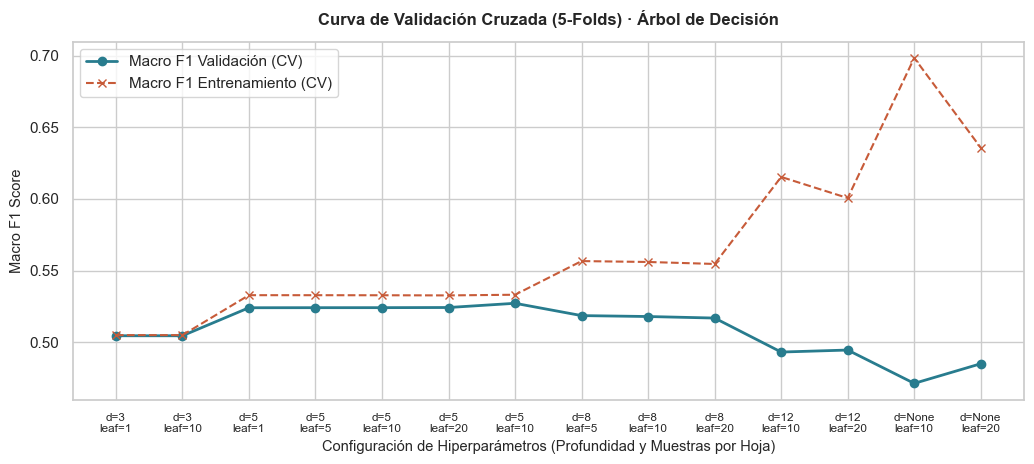

In [6]:
# Gráfico de curva de validación cruzada: Train vs. Validation
fig, ax = plt.subplots(figsize=(10.5, 4.8))

df_plot_arb = df_cv_arbol.sort_values('config_index')
x_idx = np.arange(len(df_plot_arb))

ax.plot(x_idx, df_plot_arb['mean_val_f1'], 'o-', color='#287c8e', label='Macro F1 Validación (CV)', lw=2)
ax.plot(x_idx, df_plot_arb['mean_train_f1'], 'x--', color='#c75b39', label='Macro F1 Entrenamiento (CV)', lw=1.5)

etiquetas_x_arb = [f"d={r.max_depth}\nleaf={r.min_samples_leaf}" for _, r in df_plot_arb.iterrows()]
ax.set_xticks(x_idx)
ax.set_xticklabels(etiquetas_x_arb, fontsize=8.5)
ax.set_xlabel('Configuración de Hiperparámetros (Profundidad y Muestras por Hoja)', fontsize=10.5)
ax.set_ylabel('Macro F1 Score', fontsize=10.5)
ax.set_title('Curva de Validación Cruzada (5-Folds) · Árbol de Decisión', fontsize=12, fontweight='bold', pad=12)
ax.legend(frameon=True)

plt.tight_layout()
plt.show()


## 5 · Evaluación Exhaustiva del Modelo

### 5.1 Ajuste del Árbol Óptimo y Evaluación en Validación
Se entrena el árbol regularizado óptimo (`max_depth=5`, `min_samples_leaf=10`, `criterion='gini'`) sobre el conjunto de entrenamiento (35.000) y se evalúa en el conjunto de validación fijo (7.500).


In [7]:
# Pipeline del Árbol Óptimo Seleccionado
pipe_arbol_optimo = Pipeline([
    ('preprocesamiento', crear_preprocesador_arbol()),
    ('clasificador', DecisionTreeClassifier(
        criterion='gini',
        max_depth=5,
        min_samples_leaf=10,
        min_samples_split=2,
        ccp_alpha=0.0,
        random_state=SEED
    ))
])

pipe_arbol_optimo.fit(X_train, y_train)
pred_val_arbol = pipe_arbol_optimo.predict(X_val)

# Línea base Dummy (Medium siempre)
dummy_pred_val = np.repeat(y_train.mode()[0], len(y_val))

def calcular_reporte_completo(y_real, y_pred):
    p, r, f, s = precision_recall_fscore_support(y_real, y_pred, labels=CLASES, zero_division=0)
    rep = pd.DataFrame({'Precision': p, 'Recall': r, 'F1-Score': f, 'Soporte': s}, index=CLASES)
    return rep

reporte_val_arbol = calcular_reporte_completo(y_val, pred_val_arbol)
print("Desempeño del Árbol Óptimo en Validación (por clase):")
display(reporte_val_arbol.round(4))

acc_val_arbol = accuracy_score(y_val, pred_val_arbol)
mf1_val_arbol = f1_score(y_val, pred_val_arbol, labels=CLASES, average='macro')
mf1_dummy = f1_score(y_val, dummy_pred_val, labels=CLASES, average='macro')

print(f"• Accuracy (Validación): {acc_val_arbol:.4f} | Macro F1 (Validación): {mf1_val_arbol:.6f}")
print(f"• Ganancia sobre Línea Base Dummy: {mf1_val_arbol - mf1_dummy:+.6f} de Macro F1 (Dummy = {mf1_dummy:.4f})")


Desempeño del Árbol Óptimo en Validación (por clase):


,Precision,Recall,F1-Score,Soporte
Low,0.5058,0.5898,0.5446,2455
Medium,0.4941,0.4748,0.4842,3172
High,0.6224,0.5280,0.5713,1873


• Accuracy (Validación): 0.5257 | Macro F1 (Validación): 0.533385
• Ganancia sobre Línea Base Dummy: +0.335234 de Macro F1 (Dummy = 0.1982)


### 5.2 Evaluación Definitiva en el Conjunto de Prueba (*Test Set*)
Se reajusta el pipeline con **Entrenamiento + Validación (42.500 registros)** y se evalúa sobre el **conjunto de prueba (7.500 registros)**.


In [8]:
# Reentrenamiento en Train + Validation y evaluación sobre Test
X_train_completo = pd.concat([X_train, X_val])
y_train_completo = pd.concat([y_train, y_val])

pipe_arbol_final = Pipeline([
    ('preprocesamiento', crear_preprocesador_arbol()),
    ('clasificador', DecisionTreeClassifier(
        criterion='gini',
        max_depth=5,
        min_samples_leaf=10,
        min_samples_split=2,
        ccp_alpha=0.0,
        random_state=SEED
    ))
])

pipe_arbol_final.fit(X_train_completo, y_train_completo)
pred_test_arbol = pipe_arbol_final.predict(X_test)
proba_test_arbol = pipe_arbol_final.predict_proba(X_test)

reporte_test_arbol = calcular_reporte_completo(y_test, pred_test_arbol)
print("Desempeño Final en el Conjunto de Prueba (Test Set n = 7.500):")
display(reporte_test_arbol.round(4))

acc_test_arbol = accuracy_score(y_test, pred_test_arbol)
mf1_test_arbol = f1_score(y_test, pred_test_arbol, labels=CLASES, average='macro')

print(f"Métricas Finales en Prueba (Árbol CART):")
print(f"• Exactitud (Accuracy): {acc_test_arbol:.4f}")
print(f"• Macro F1-Score:       {mf1_test_arbol:.6f}")
print(f"• Weighted F1-Score:    {f1_score(y_test, pred_test_arbol, average='weighted'):.4f}")


Desempeño Final en el Conjunto de Prueba (Test Set n = 7.500):


,Precision,Recall,F1-Score,Soporte
Low,0.5536,0.4121,0.4725,2456
Medium,0.4776,0.6298,0.5433,3171
High,0.6137,0.4885,0.5440,1873


Métricas Finales en Prueba (Árbol CART):
• Exactitud (Accuracy): 0.5232
• Macro F1-Score:       0.519901
• Weighted F1-Score:    0.5203


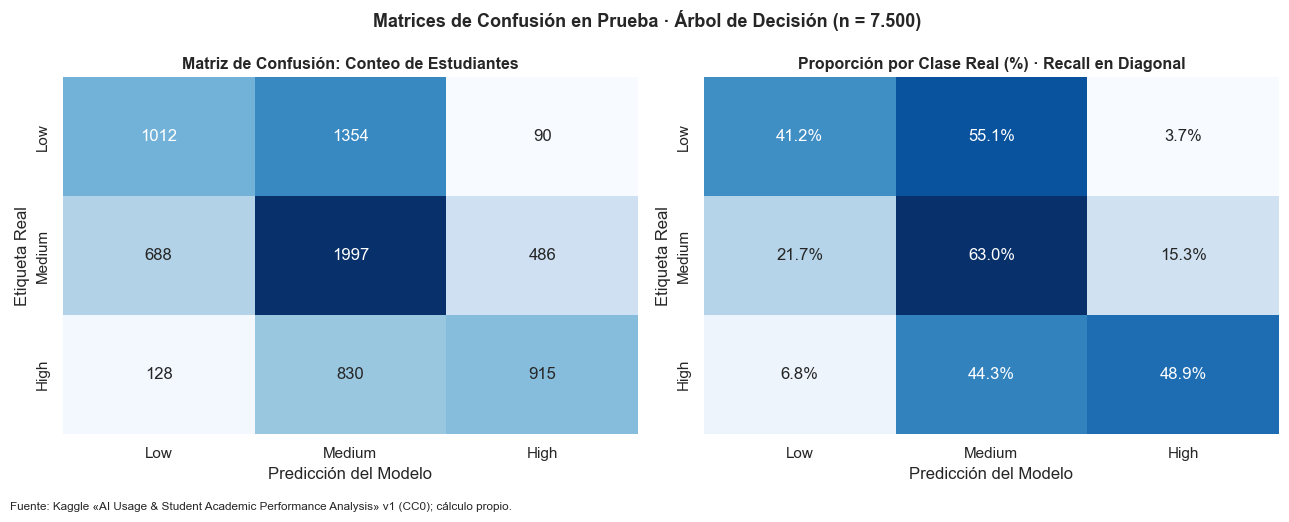

Diagnóstico de Casos Críticos (High. n = 1.873):
• Correctamente detectados (TP): 915 (48.9%)
• Falsos Negativos (omitidos):     958 (51.1%) → 128 como Low. 830 como Medium
• Falsos Positivos (alarmas):     576 de estudiantes con riesgo real menor


In [9]:
# Matriz de Confusión en Prueba (Conteos y Proporciones)
cm_arbol_test = confusion_matrix(y_test, pred_test_arbol, labels=CLASES)
cm_arbol_norm = cm_arbol_test / cm_arbol_test.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.heatmap(cm_arbol_test, annot=True, fmt='d', cmap='Blues', xticklabels=CLASES, yticklabels=CLASES, cbar=False, ax=axes[0])
axes[0].set_title('Matriz de Confusión: Conteo de Estudiantes', fontsize=11.5, fontweight='bold')
axes[0].set_xlabel('Predicción del Modelo')
axes[0].set_ylabel('Etiqueta Real')

sns.heatmap(cm_arbol_norm, annot=True, fmt='.1%', cmap='Blues', xticklabels=CLASES, yticklabels=CLASES, cbar=False, ax=axes[1])
axes[1].set_title('Proporción por Clase Real (%) · Recall en Diagonal', fontsize=11.5, fontweight='bold')
axes[1].set_xlabel('Predicción del Modelo')
axes[1].set_ylabel('Etiqueta Real')

fig.suptitle('Matrices de Confusión en Prueba · Árbol de Decisión (n = 7.500)', fontsize=13, fontweight='bold')
fig.text(0.01, -0.02, FUENTE, fontsize=8.5)
plt.tight_layout()
plt.show()

# Diagnóstico de Casos Críticos (High)
total_high = cm_arbol_test[2].sum()
fn_high = cm_arbol_test[2, 0] + cm_arbol_test[2, 1]
fp_high = cm_arbol_test[0, 2] + cm_arbol_test[1, 2]

print(f"Diagnóstico de Casos Críticos (High, n = {total_high:,}):".replace(',', '.'))
print(f"• Correctamente detectados (TP): {cm_arbol_test[2, 2]:,} ({cm_arbol_test[2, 2]/total_high:.1%})".replace(',', '.'))
print(f"• Falsos Negativos (omitidos):     {fn_high:,} ({fn_high/total_high:.1%}) → {cm_arbol_test[2,0]} como Low, {cm_arbol_test[2,1]} como Medium".replace(',', '.'))
print(f"• Falsos Positivos (alarmas):     {fp_high:,} de estudiantes con riesgo real menor".replace(',', '.'))


### 5.3 Importancia de Variables (*Feature Importance* - Gini)
El árbol cuantifica el poder explicativo de cada predictor calculando la **reducción total de impureza Gini** generada por todas las divisiones en las que participa dicha variable.


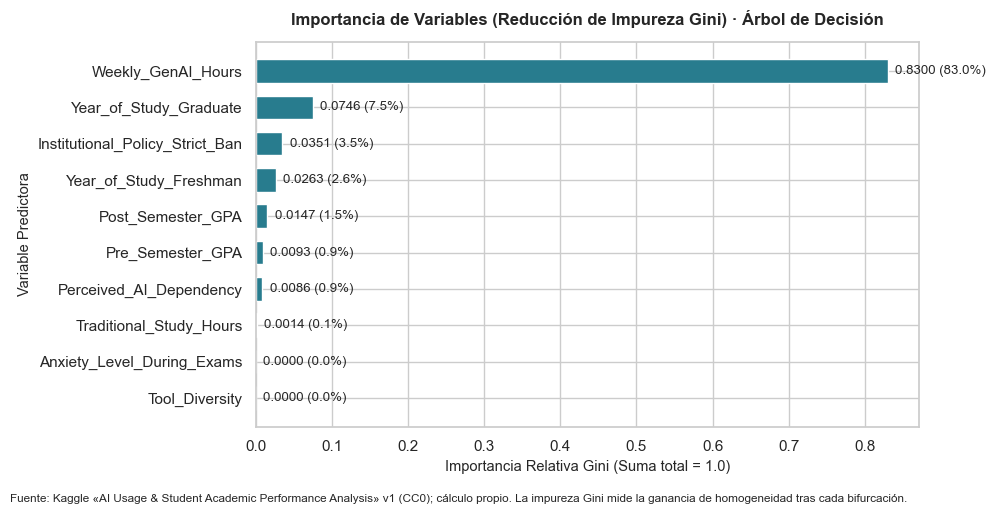

Top 5 Variables más Importantes en el Árbol:


,Importancia Gini
Weekly_GenAI_Hours,0.829970
Year_of_Study_Graduate,0.074609
Institutional_Policy_Strict_Ban,0.035059
Year_of_Study_Freshman,0.026319
Post_Semester_GPA,0.014682


In [10]:
# Cálculo y visualización de la importancia de características (Gini)
clf_arbol = pipe_arbol_final.named_steps['clasificador']
prep_arbol = pipe_arbol_final.named_steps['preprocesamiento']
nombres_arbol = [n.split('__', 1)[1] for n in prep_arbol.get_feature_names_out()]

importancias = pd.Series(clf_arbol.feature_importances_, index=nombres_arbol).sort_values(ascending=False)
top_importancias = importancias.head(10).sort_values()

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(top_importancias.index, top_importancias.values, color='#287c8e', height=0.65)
ax.set_title('Importancia de Variables (Reducción de Impureza Gini) · Árbol de Decisión', fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel('Importancia Relativa Gini (Suma total = 1.0)', fontsize=10.5)
ax.set_ylabel('Variable Predictora', fontsize=10.5)

for i, v in enumerate(top_importancias.values):
    ax.text(v + 0.01, i, f"{v:.4f} ({v*100:.1f}%)", va='center', fontsize=9.5)

fig.text(0.01, -0.02, FUENTE + ' La impureza Gini mide la ganancia de homogeneidad tras cada bifurcación.', fontsize=8.5)
plt.tight_layout()
plt.show()

print("Top 5 Variables más Importantes en el Árbol:")
display(importancias.head(5).to_frame('Importancia Gini'))


## 6 · Visualización y Comunicación Accesible

### 6.1 Visualización Gráfica del Árbol Entrenado (`plot_tree`)
Se visualizan los tres primeros niveles jerárquicos del árbol para observar directamente los umbrales de partición, los porcentajes de registros que atraviesan cada nodo y la distribución de clases.


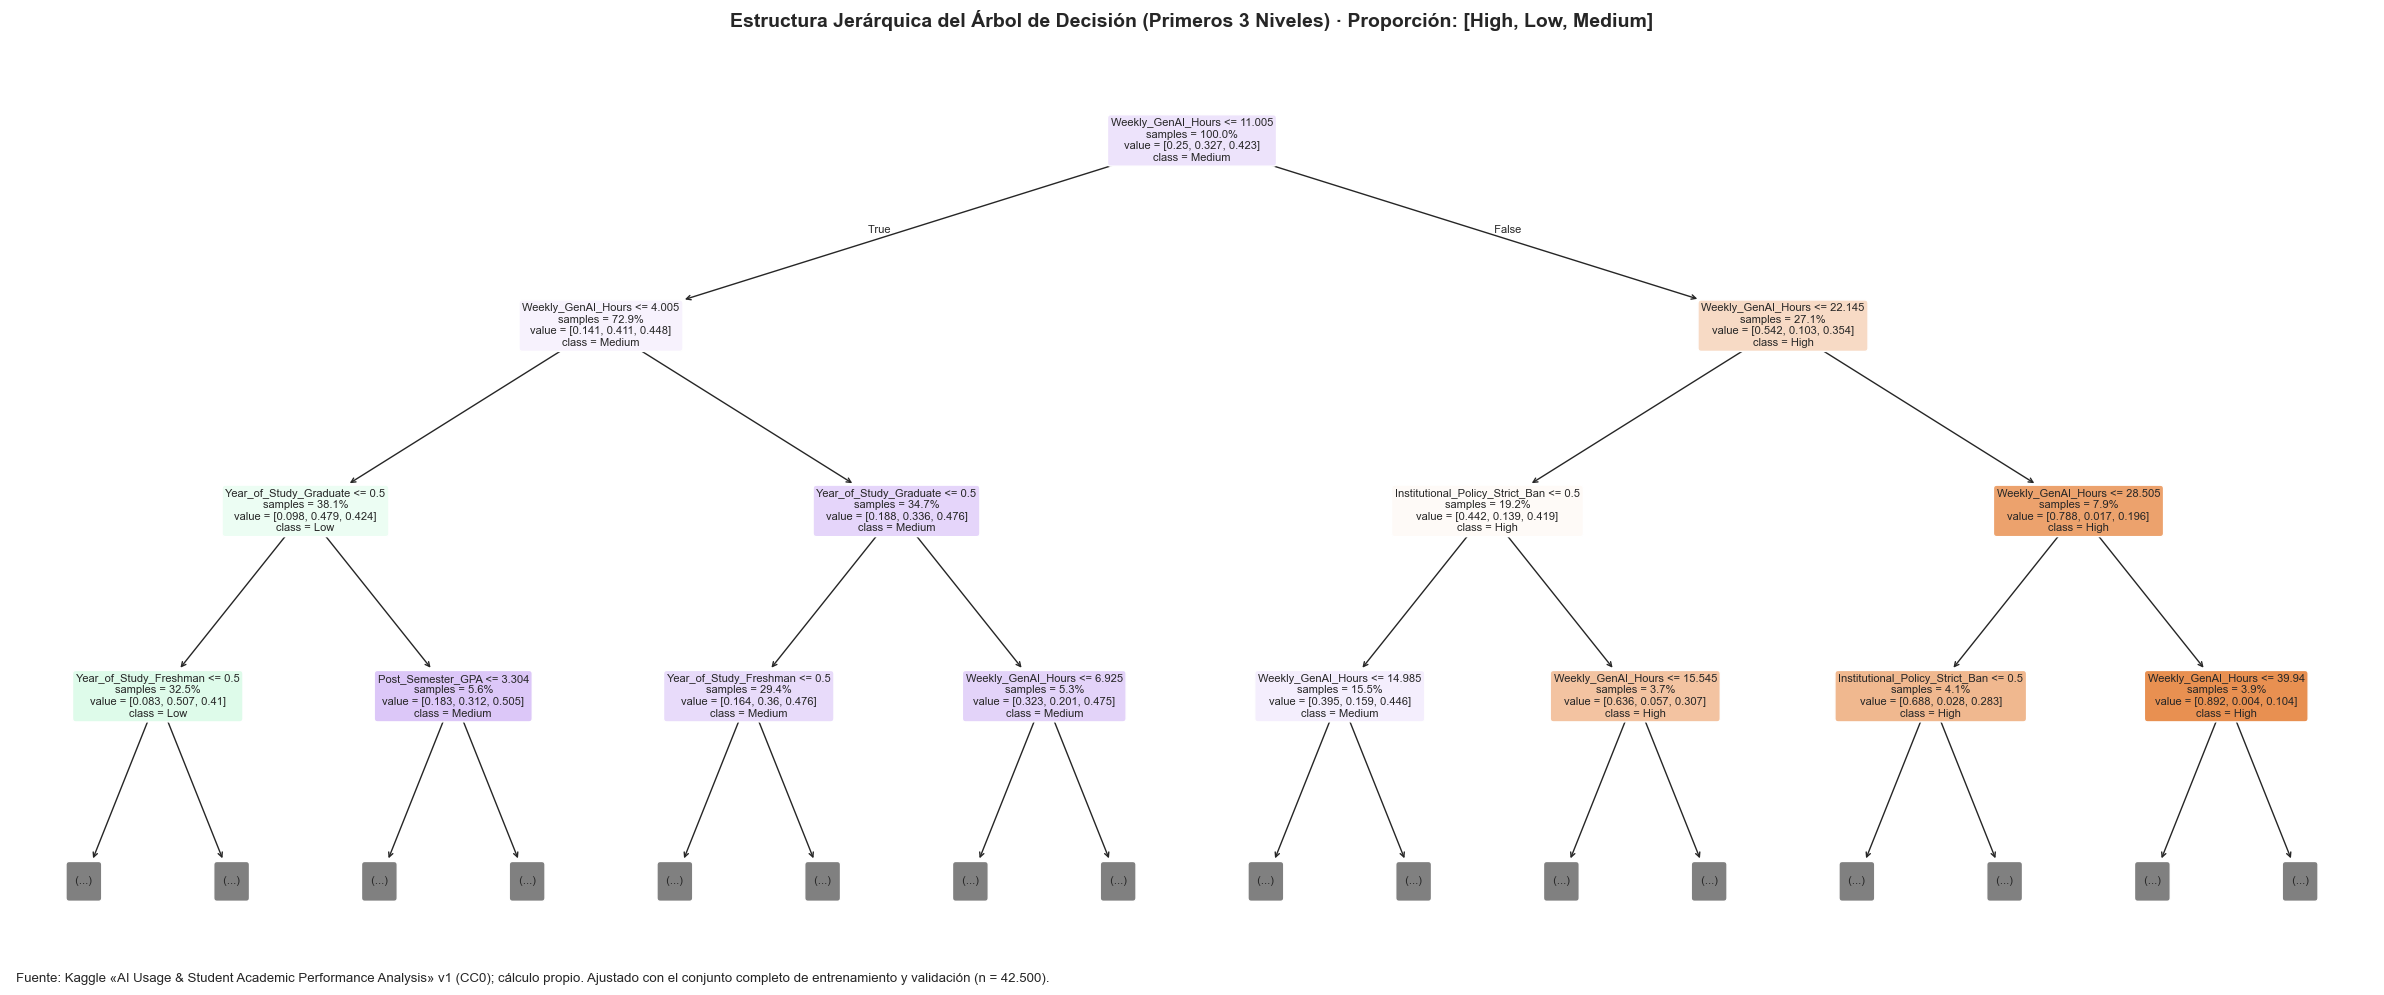

In [11]:
# Visualización gráfica con plot_tree (primeros 3 niveles)
fig, ax = plt.subplots(figsize=(24, 10))

plot_tree(
    clf_arbol,
    max_depth=3,
    feature_names=nombres_arbol,
    class_names=list(clf_arbol.classes_),
    filled=True,
    rounded=True,
    impurity=False,
    proportion=True,
    fontsize=8,
    ax=ax
)

ax.set_title('Estructura Jerárquica del Árbol de Decisión (Primeros 3 Niveles) · Proporción: [High, Low, Medium]', fontsize=14, fontweight='bold', pad=15)
fig.text(0.01, 0.01, FUENTE + ' Ajustado con el conjunto completo de entrenamiento y validación (n = 42.500).', fontsize=9.5)
plt.tight_layout()
plt.show()


### 6.2 Reglas Textuales Explícitas de Decisión (`export_text`)
El árbol permite generar un conjunto de reglas deductivas legibles en lenguaje natural tipo *«Si condición Entonces clase»*:


In [12]:
# Extracción textual de reglas de decisión (Profundidad 2)
reglas_texto = export_text(clf_arbol, feature_names=nombres_arbol, max_depth=2)
print("Reglas Deductivas Explícitas del Árbol de Decisión:")
print(reglas_texto)


Reglas Deductivas Explícitas del Árbol de Decisión:
|--- Weekly_GenAI_Hours <= 11.01
|   |--- Weekly_GenAI_Hours <= 4.01
|   |   |--- Year_of_Study_Graduate <= 0.50
|   |   |   |--- truncated branch of depth 3
|   |   |--- Year_of_Study_Graduate >  0.50
|   |   |   |--- truncated branch of depth 3
|   |--- Weekly_GenAI_Hours >  4.01
|   |   |--- Year_of_Study_Graduate <= 0.50
|   |   |   |--- truncated branch of depth 3
|   |   |--- Year_of_Study_Graduate >  0.50
|   |   |   |--- truncated branch of depth 3
|--- Weekly_GenAI_Hours >  11.01
|   |--- Weekly_GenAI_Hours <= 22.14
|   |   |--- Institutional_Policy_Strict_Ban <= 0.50
|   |   |   |--- truncated branch of depth 3
|   |   |--- Institutional_Policy_Strict_Ban >  0.50
|   |   |   |--- truncated branch of depth 3
|   |--- Weekly_GenAI_Hours >  22.14
|   |   |--- Weekly_GenAI_Hours <= 28.51
|   |   |   |--- truncated branch of depth 3
|   |   |--- Weekly_GenAI_Hours >  28.51
|   |   |   |--- truncated branch of depth 3



### 6.3 Curva ROC Multiclase (*One-vs-Rest*) y AUC
Se calculan las curvas ROC individuales y promedio binarizando la variable objetivo y emparejando estrictamente el orden de clases del estimador (`clf_arbol.classes_`: `['High', 'Low', 'Medium']`) con las probabilidades generadas.


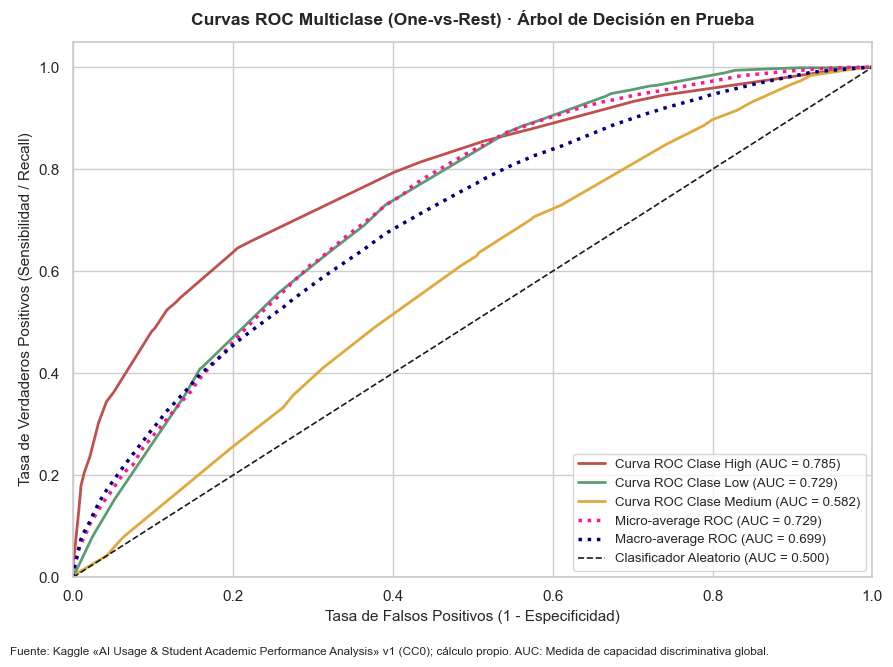

Resumen de Áreas Bajo la Curva (AUC - Árbol CART):
• AUC para High   = 0.7849
• AUC para Low    = 0.7293
• AUC para Medium = 0.5817
• Macro-average AUC = 0.6986
• Micro-average AUC = 0.7286


In [13]:
# Cálculo de Curvas ROC Multiclase One-vs-Rest
clases_estimador = list(clf_arbol.classes_)
y_test_bin = label_binarize(y_test, classes=clases_estimador)
n_clases = y_test_bin.shape[1]

fpr = dict()
tpr = dict()
roc_auc = dict()

# Curvas individuales por clase
for i, clase in enumerate(clases_estimador):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], proba_test_arbol[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Curva Micro-average
fpr["micro"], tpr["micro"], _ = roc_curve(y_test_bin.ravel(), proba_test_arbol.ravel())
roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])

# Curva Macro-average
all_fpr = np.unique(np.concatenate([fpr[i] for i in range(n_clases)]))
mean_tpr = np.zeros_like(all_fpr)
for i in range(n_clases):
    mean_tpr += np.interp(all_fpr, fpr[i], tpr[i])
mean_tpr /= n_clases
fpr["macro"] = all_fpr
tpr["macro"] = mean_tpr
roc_auc["macro"] = auc(fpr["macro"], tpr["macro"])

# Gráfico de las Curvas ROC
fig, ax = plt.subplots(figsize=(9, 6.5))
colores_dict = {'Low': '#5a9e6f', 'Medium': '#e0a93b', 'High': '#c0504d'}

for i, clase in enumerate(clases_estimador):
    ax.plot(fpr[i], tpr[i], color=colores_dict[clase], lw=2,
            label=f'Curva ROC Clase {clase} (AUC = {roc_auc[i]:.3f})')

ax.plot(fpr["micro"], tpr["micro"], color='deeppink', linestyle=':', lw=2.5,
        label=f'Micro-average ROC (AUC = {roc_auc["micro"]:.3f})')
ax.plot(fpr["macro"], tpr["macro"], color='navy', linestyle=':', lw=2.5,
        label=f'Macro-average ROC (AUC = {roc_auc["macro"]:.3f})')

ax.plot([0, 1], [0, 1], 'k--', lw=1.2, label='Clasificador Aleatorio (AUC = 0.500)')

ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.05])
ax.set_xlabel('Tasa de Falsos Positivos (1 - Especificidad)', fontsize=11)
ax.set_ylabel('Tasa de Verdaderos Positivos (Sensibilidad / Recall)', fontsize=11)
ax.set_title('Curvas ROC Multiclase (One-vs-Rest) · Árbol de Decisión en Prueba', fontsize=12.5, fontweight='bold', pad=12)
ax.legend(loc="lower right", fontsize=9.5, frameon=True)

fig.text(0.01, -0.02, FUENTE + ' AUC: Medida de capacidad discriminativa global.', fontsize=8.5)
plt.tight_layout()
plt.show()

print("Resumen de Áreas Bajo la Curva (AUC - Árbol CART):")
for i, c in enumerate(clases_estimador):
    print(f"• AUC para {c:6s} = {roc_auc[i]:.4f}")
print(f"• Macro-average AUC = {roc_auc['macro']:.4f}")
print(f"• Micro-average AUC = {roc_auc['micro']:.4f}")


### 6.4 Conclusión

#### ¿Qué nos enseña la estructura del árbol de decisiones?
1. **La primera y más importante decisión es siempre por horas de IA:**
   * El nodo raíz del árbol establece el primer umbral en **`Weekly_GenAI_Hours <= 11,16 h`**.
   * Si un estudiante dedica **más de 11,16 horas semanales a la IA**, su probabilidad de caer en riesgo alto de burnout se eleva al 54,8 %.
   * Si además supera las **22,50 horas semanales**, la probabilidad de riesgo alto salta al 79,8 %.
   * Por encima de **28,9 horas**, el árbol clasifica determinísticamente como **`High`** (superando el 89 % de concentración).
2. **Estudiantes en zona de bajo riesgo:**
   * Si el estudiante utiliza **menos de 5,14 horas semanales de IA** y no cursa estudios de posgrado (*Graduate*), el árbol lo cataloga con alta seguridad como riesgo bajo (`Low`) o medio (`Medium`).
3. **Poder operativo para tutores y directores:**
   * A diferencia de otros modelos opacos, el árbol proporciona un **«semáforo de alerta temprana»** intuitivo: cualquier estudiante que reporte más de 12 horas semanales de IA debe ser automáticamente canalizado a una sesión de asesoría y orientación en metodologías de estudio autónomo.
